# TP3 — Évaluation : mesurer pour choisir — **corrigé**

*Version corrigée : identique au TP, avec les bonus résolus (les bonus 1 à 4 tournent sans clé d'API).*

Depuis ce matin, on a fait des choix : découpage, modèle d'embeddings, `k`, recherche sémantique ou hybride, prompt,
modèle de génération… Et on les a jugés sur trois questions. Ce n'est pas une mesure.

Comment comparer objectivement deux variantes ? Il faut deux ingrédients :

- un **jeu de test** : des questions dont on connaît la réponse ;
- une **métrique** : un chiffre qui dit si le système a trouvé la réponse.

Le parcours de base montre **une** manière d'évaluer le système : une méthode de recherche, une métrique, un chiffre.
Les bonus ajoutent d'autres méthodes, d'autres métriques, puis l'évaluation des réponses du LLM.

Plan :
1. Un jeu de questions
2. Évaluer la recherche sémantique avec le hit@k

Pour aller plus loin (bonus, dans l'ordre de votre choix) :
- Bonus 1 — une deuxième métrique : le MRR
- Bonus 2 — une deuxième méthode : la recherche par mots-clés (BM25)
- Bonus 3 — comparer deux découpages
- Bonus 4 — mesurer vos améliorations du TP1
- Bonus 5 — faire générer des questions par le LLM
- Bonus 6 — évaluer la génération avec un LLM juge
- Bonus 7 — un juge fiable ?
- Bonus 8 — les questions pièges

In [1]:
import json
import re

import numpy as np
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from litellm import completion

import settings
from rag import load_index, load_pdfs, chunk_pages, embed, search, search_bm25, answer

load_dotenv()
chunks, embeddings = load_index()

## 1. Un jeu de questions

Une question de test = `{"question", "source", "pages"}` : la réponse se trouve à l'une de ces pages de ce document
(une même information figure souvent à plusieurs endroits : résumé, tableau, texte).
On repère la réponse par sa **page** et non par un numéro de chunk : le jeu reste valable si on change le découpage.

Le fichier `eval/questions.json` contient une vingtaine de questions écrites à la main et vérifiées.

In [2]:
with open("eval/questions.json", encoding="utf-8") as f:
    jeu_test = json.load(f)

print(len(jeu_test), "questions")
for item in jeu_test[:5]:
    print(f"- {item['question']}  →  {item['source']} p.{item['pages']}")

26 questions
- Quelle est la tension d'alimentation du HC-SR04 ?  →  hcsr04.pdf p.[1]
- Quelle est la portée de mesure du capteur ultrason HC-SR04 ?  →  hcsr04.pdf p.[1]
- Quelle durée minimale doit avoir l'impulsion de déclenchement (trigger) du HC-SR04 ?  →  hcsr04.pdf p.[1, 2]
- Quel est le courant de fonctionnement du HC-SR04 ?  →  hcsr04.pdf p.[1]
- Combien de broches GPIO le Raspberry Pi Pico expose-t-il ?  →  pico.pdf p.[4]


## 2. Évaluer la recherche sémantique avec le hit@k

On prend **une méthode**, la recherche sémantique du TP1 (`search`), et **une métrique**, le hit@k.

Pour chaque question, on lance la recherche et on note **à quel rang** apparaît la bonne page.
Le **hit@k** est la proportion de questions dont la bonne page figure dans les k premiers résultats.
Exemple : hit@5 = 0,8 signifie que, dans 80 % des cas, le LLM aura la bonne page sous les yeux avec `k = 5`.

In [3]:
def rang_bonne_page(item, resultats_recherche):
    """Rang (à partir de 1) du premier chunk issu de la bonne page ; None si elle est absente."""
    for rang, r in enumerate(resultats_recherche, start=1):
        if r["source"] == item["source"] and r["page"] in item["pages"]:
            return rang
    return None


def evaluer_retrieval(fonction_recherche, jeu_test, k_max=10):
    """Lance la recherche sur chaque question et renvoie la liste des rangs de la bonne page.

    fonction_recherche(question, k) -> liste de chunks
    """
    return [rang_bonne_page(item, fonction_recherche(item["question"], k_max)) for item in jeu_test]


def hit_at_k(rangs, k):
    """Proportion de questions dont la bonne page est dans les k premiers résultats."""
    return float(np.mean([rang is not None and rang <= k for rang in rangs]))


semantique = lambda q, k: search(q, chunks, embeddings, k)
rangs = evaluer_retrieval(semantique, jeu_test)

for item, rang in zip(jeu_test, rangs):
    print(f"rang {rang or '-':>2}  {item['question']}")
print(f"\nhit@1 = {hit_at_k(rangs, 1):.2f}   hit@5 = {hit_at_k(rangs, 5):.2f}   hit@10 = {hit_at_k(rangs, 10):.2f}")

rang  -  Quelle est la tension d'alimentation du HC-SR04 ?
rang  1  Quelle est la portée de mesure du capteur ultrason HC-SR04 ?
rang  2  Quelle durée minimale doit avoir l'impulsion de déclenchement (trigger) du HC-SR04 ?
rang  4  Quel est le courant de fonctionnement du HC-SR04 ?
rang  3  Combien de broches GPIO le Raspberry Pi Pico expose-t-il ?
rang  2  Quelle quantité de SRAM contient le RP2040 du Raspberry Pi Pico ?
rang  7  Quelle est la fréquence maximale du processeur du Raspberry Pi Pico ?
rang  -  À quelle broche GPIO est reliée la LED utilisateur du Raspberry Pi Pico ?
rang  -  Quelle est la fréquence maximale du processeur de l'ESP32 ?
rang  1  Quelle quantité de SRAM embarque l'ESP32 ?
rang  1  Combien de GPIO programmables possède l'ESP32 ?
rang  1  Quelles normes Wi-Fi l'ESP32 supporte-t-il ?
rang  3  Quelle est la consommation de courant du BME280 en mode veille (sleep) ?
rang  -  Quelle est la plage de pression mesurable par le BME280 ?
rang  -  Quelle est la plage de

sémantique                   hit@1=0.31  hit@5=0.69  hit@10=0.77


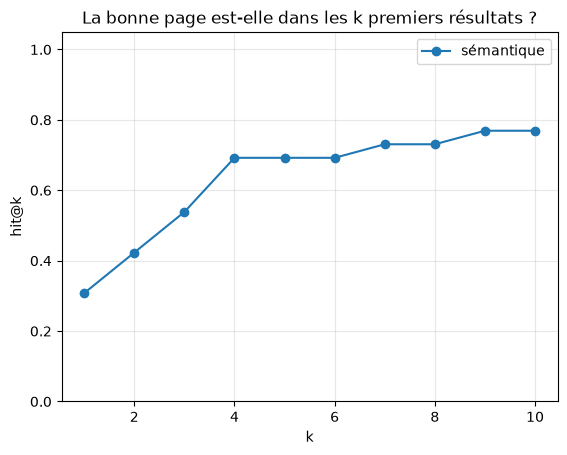

In [4]:
def afficher_resultats(resultats):
    """Tableau et courbes hit@k de toutes les variantes mesurées (resultats = {nom: rangs})."""
    for nom, rangs_variante in resultats.items():
        print(f"{nom:<28} hit@1={hit_at_k(rangs_variante, 1):.2f}  hit@5={hit_at_k(rangs_variante, 5):.2f}  "
              f"hit@10={hit_at_k(rangs_variante, 10):.2f}")
        plt.plot(range(1, 11), [hit_at_k(rangs_variante, k) for k in range(1, 11)], marker="o", label=nom)
    plt.xlabel("k"); plt.ylabel("hit@k"); plt.ylim(0, 1.05); plt.grid(alpha=0.3); plt.legend()
    plt.title("La bonne page est-elle dans les k premiers résultats ?")
    plt.show()


resultats = {"sémantique": rangs}  # les bonus y ajoutent leurs variantes
afficher_resultats(resultats)

**À observer**

- La courbe monte avec k : plus on donne de chunks au LLM, plus la bonne page a de chances d'y être.
  En contrepartie, chaque chunk coûte des tokens.
- Le point où la courbe plafonne aide à choisir `settings.TOP_K`.
- Quelles questions échouent (rang `-`) ? Identifiant exact, question en français sur une datasheet en anglais,
  petit document noyé parmi les gros… Ce sont autant de pistes d'amélioration.

**Vous avez une évaluation complète** : un jeu de test, une méthode, une métrique, un chiffre.
Pour juger un réglage, on le change, on relance ces deux cellules et on compare le hit@5.
Les bonus ci-dessous approfondissent chaque ingrédient.

## Pour aller plus loin (bonus)

Les bonus sont indépendants : faites-les dans l'ordre de votre choix. Seul le bonus 7 demande d'avoir exécuté le bonus 6.
Les bonus 1 à 4 tournent sans clé d'API ; les bonus 5 à 8 appellent le LLM.

### Bonus 1 — Une deuxième métrique : le MRR

Le hit@k répond par oui ou par non : la bonne page est-elle dans le top k ? Il ne distingue pas une bonne page
au rang 1 d'une bonne page au rang 5.

Le **MRR** (*Mean Reciprocal Rank*, rang réciproque moyen) fait cette différence. C'est la moyenne de 1/rang de la
bonne page, avec 0 si elle est absente : rang 1 → 1 ; rang 2 → 0,5 ; rang 5 → 0,2.
Plus le MRR est proche de 1, plus la bonne page arrive haut.

In [5]:
def mrr(rangs):
    """Moyenne de 1/rang de la bonne page (0 quand elle est absente)."""
    return float(np.mean([1 / rang if rang else 0 for rang in rangs]))


for nom, rangs_variante in resultats.items():  # toutes les variantes mesurées jusqu'ici
    print(f"{nom:<28} hit@5={hit_at_k(rangs_variante, 5):.2f}  MRR={mrr(rangs_variante):.2f}")

sémantique                   hit@5=0.69  MRR=0.45


**À observer**

Deux variantes peuvent avoir le même hit@5 et des MRR différents. Celle qui place la bonne page plus haut
permet de réduire `k` sans la perdre, donc d'envoyer moins de tokens au LLM.
Relancez cette cellule après les autres bonus pour comparer toutes vos variantes.

### Bonus 2 — Une deuxième méthode : la recherche par mots-clés (BM25)

Même jeu de test, même métrique, autre méthode : `search_bm25` du TP1. On l'ajoute au tableau `resultats`
et on compare les courbes.

sémantique                   hit@1=0.31  hit@5=0.69  hit@10=0.77
BM25                         hit@1=0.08  hit@5=0.46  hit@10=0.62


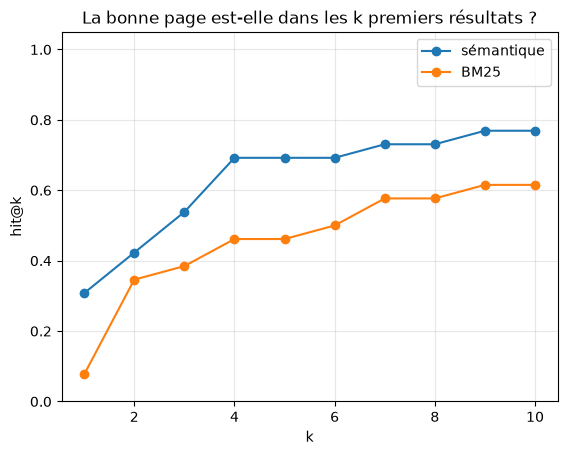

In [6]:
mots_cles = lambda q, k: search_bm25(q, chunks, k)
resultats["BM25"] = evaluer_retrieval(mots_cles, jeu_test)
afficher_resultats(resultats)

**À observer**

- Laquelle gagne sur ce jeu ? Cela dépend des questions (identifiants exacts ou paraphrases), de la langue et du
  découpage. D'où l'intérêt d'un jeu de test **représentatif des vraies questions des utilisateurs**.
- Rappel du TP1 : ce BM25 compte aussi les mots vides (`de`, `la`, `est`…). Le bonus 4 mesure la version sans mots vides.

### Bonus 3 — Comparer deux découpages

Même méthode pour le découpage : on reconstruit un index avec d'autres paramètres, et on mesure.
Ici, des chunks deux fois plus grands (300 mots au lieu de 150). Le calcul des embeddings prend 1 à 2 minutes.

361 chunks de 300 mots (contre 601 de 150)

sémantique                   hit@1=0.31  hit@5=0.69  hit@10=0.77
BM25                         hit@1=0.08  hit@5=0.46  hit@10=0.62
sémantique, chunks 300       hit@1=0.46  hit@5=0.69  hit@10=0.81


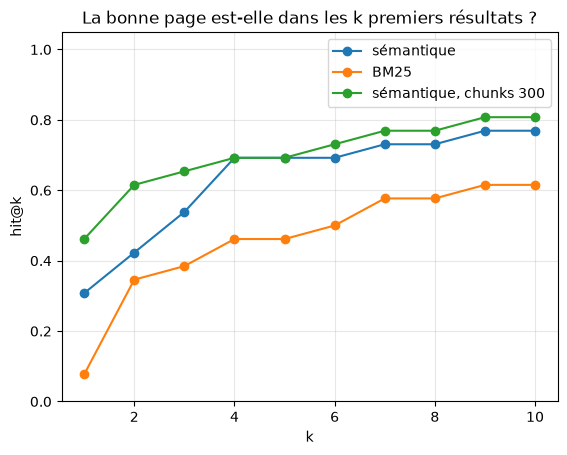

In [7]:
pages = load_pdfs()
chunks_300 = chunk_pages(pages, chunk_size=300, overlap=50)
embeddings_300 = embed([c["text"] for c in chunks_300])
print(len(chunks_300), "chunks de 300 mots (contre", len(chunks), "de 150)\n")

resultats["sémantique, chunks 300"] = evaluer_retrieval(lambda q, k: search(q, chunks_300, embeddings_300, k), jeu_test)
afficher_resultats(resultats)

**À observer**

Des chunks plus grands contiennent plus souvent la réponse (moins de coupures), mais ils sont moins précis et coûtent
plus de tokens. Il n'y a pas de bonne taille universelle : elle dépend des documents et des questions.
**On la choisit en mesurant.**

### Bonus 4 — Mesurer vos améliorations du TP1

BM25 sans mots vides, recherche hybride, découpage par paragraphes : chaque variante s'ajoute au tableau `resultats`
et se compare à la base. Quelle combinaison gagne ? Comparez vos chiffres entre groupes.

La cellule importe les fonctions du **corrigé du TP1** (`solutions/tp1.py`, fourni en fin de TP1) : pas besoin d'avoir
terminé le TP1 pour faire ce bonus. Vous préférez vos propres fonctions ? Collez-les sous l'import : elles remplacent
celles du corrigé.

L'index par paragraphes est rechargé depuis `index_paragraphes/` s'il a été sauvegardé au TP1, recalculé sinon
(2 à 3 min).

sémantique                   hit@1=0.31  hit@5=0.69  hit@10=0.77
BM25                         hit@1=0.08  hit@5=0.46  hit@10=0.62
sémantique, chunks 300       hit@1=0.46  hit@5=0.69  hit@10=0.81
BM25 sans mots vides         hit@1=0.50  hit@5=0.69  hit@10=0.85
hybride (RRF)                hit@1=0.42  hit@5=0.77  hit@10=0.88
sémantique, par paragraphes  hit@1=0.54  hit@5=0.77  hit@10=0.85
hybride + par paragraphes    hit@1=0.54  hit@5=0.96  hit@10=0.96


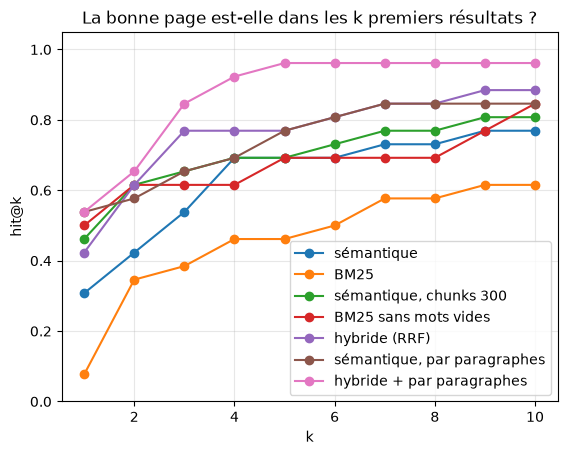

In [8]:
from pathlib import Path

try:
    from solutions.tp1 import search_bm25_sans_mots_vides, search_hybrid, chunk_pages_par_paragraphes
except ModuleNotFoundError:
    print("Corrigé du TP1 absent (solutions/tp1.py) : collez vos fonctions ci-dessous.")

# Collez ici vos fonctions du TP1 si vous préférez les vôtres : MOTS_VIDES, tokenize_sans_mots_vides,
# search_bm25_sans_mots_vides, search_hybrid, chunk_pages_par_paragraphes.


# -- BM25 sans mots vides, puis recherche hybride --
resultats["BM25 sans mots vides"] = evaluer_retrieval(lambda q, k: search_bm25_sans_mots_vides(q, chunks, k), jeu_test)
resultats["hybride (RRF)"] = evaluer_retrieval(lambda q, k: search_hybrid(q, chunks, embeddings, k), jeu_test)

# -- découpage par paragraphes : index sauvegardé au TP1 (exercice 2), sinon recalculé --
if Path("index_paragraphes").exists():
    chunks_paragraphes, embeddings_paragraphes = load_index("index_paragraphes")
else:
    chunks_paragraphes = chunk_pages_par_paragraphes(load_pdfs())
    embeddings_paragraphes = embed([c["text"] for c in chunks_paragraphes])  # 2 à 3 min
resultats["sémantique, par paragraphes"] = evaluer_retrieval(
    lambda q, k: search(q, chunks_paragraphes, embeddings_paragraphes, k), jeu_test)
resultats["hybride + par paragraphes"] = evaluer_retrieval(
    lambda q, k: search_hybrid(q, chunks_paragraphes, embeddings_paragraphes, k), jeu_test)

afficher_resultats(resultats)

**Correction, bonus 4** — ordres de grandeur attendus avec l'index de référence (26 questions : chaque question
pèse ±0,04, ne pas sur-interpréter les petits écarts) :

| variante | hit@5 | MRR |
|---|---|---|
| sémantique seule | 0,69 | 0,45 |
| BM25 (bonus 2) | 0,46 | 0,27 |
| BM25 sans mots vides | 0,69 | 0,59 |
| hybride (RRF) | 0,77 | 0,59 |
| sémantique, par paragraphes | 0,77 | 0,62 |
| **hybride + par paragraphes** | **0,96** | **0,69** |

Lecture : chaque exercice du TP1 apporte un gain mesurable, et les gains se **cumulent** : de 0,69 à 0,96 de hit@5
entre le RAG de base et la version améliorée. À noter : sur les trois questions de démo du TP1, le découpage par
paragraphes *semblait* moins bon. C'est la mesure qui révèle qu'il est meilleur.

### Bonus 5 — Faire générer des questions par le LLM

Écrire des questions à la main prend du temps. On peut en faire **générer** par le LLM : on tire des chunks au hasard
et on lui demande, pour chacun, une question à laquelle le chunk répond. La vérité terrain est la page du chunk.

Comptez une vingtaine d'appels à l'API. Regardez les questions produites : certaines seront mauvaises (chunk de tableau
illisible, question ambiguë). La qualité du jeu de test conditionne toute la mesure : en pratique, on relit et on trie.

In [9]:
import random

PROMPT_QUESTION = """Voici un extrait d'une datasheet de composant électronique :

---
{texte}
---

Écris UNE question précise, en français, à laquelle cet extrait permet de répondre (une valeur, une caractéristique, un comportement).
La question doit se comprendre seule : nomme le composant. Réponds uniquement par la question."""

random.seed(0)
echantillon = [c for c in random.sample(chunks, 40) if len(c["text"].split()) > 100][:20]

questions_synthetiques = []
for c in echantillon:
    reponse = completion(
        model=settings.GENERATION_MODEL,
        messages=[{"role": "user", "content": PROMPT_QUESTION.format(texte=c["text"])}],
        temperature=0, max_tokens=100,
    )
    question = reponse.choices[0].message.content.strip()
    questions_synthetiques.append({"question": question, "source": c["source"], "pages": [c["page"]]})
    print(f"- {question}  →  {c['source']} p.{c['page']}")
    print(f"    extrait : {c['text'][:200]!r}\n")  # pour juger si la question est bonne

# Pour les ajouter au jeu de test après relecture :
# jeu_test += questions_synthetiques

- Quelle est la précision de mesure en degrés Celsius du composant LM35 à une température ambiante de 25°C ?  →  lm35.pdf p.9
- Quelle est la plage de température de fonctionnement du capteur combiné d'humidité et de pression BME280 de Bosch Sensortec ?  →  bme280.pdf p.2
- Quelle est la date de révision de la datasheet du composant mentionné dans l'extrait ?  →  pico.pdf p.3
- Quelle est la précision de mesure en degrés Celsius du composant LM35A à une température ambiante de 25°C ?  →  lm35.pdf p.5
- Quelle est la tension maximale recommandée pour l'alimentation du domaine **VDD3P3_RTC** du composant **ESP32** ?  →  esp32.pdf p.51
- Quelle est la hauteur maximale du boîtier TO-92 (LP0003A) selon cette datasheet ?  →  lm35.pdf p.33
- Quelle est la configuration des résistances de pull-up ou pull-down (wpu/wpd) et les directions des buffers d'entrée/sortie (oe/ie) pour le brochage GPIO12 du composant ?  →  esp32.pdf p.69
- Quel est le composant électronique concerné par les mises à jou

### Bonus 6 — Évaluer la génération avec un LLM juge

Jusqu'ici, on a mesuré la recherche. Mais la réponse finale est-elle correcte ? C'est un texte libre : pas de
métrique simple. La pratique courante consiste à demander à un LLM de **juger**. On lui donne la question, le passage
source (la vérité) et la réponse du RAG ; il note de 0 à 10 et justifie sa note.

Gardez ses limites en tête : le juge peut se tromper, il a des biais (il aime les réponses longues) et chaque note
coûte un appel. On vérifie donc toujours un échantillon à la main. Ici, nous n'avons qu'un modèle : le juge est donc celui qui répond
(`settings.GENERATION_MODEL`). Idéalement, on choisit un juge au moins aussi bon que le modèle évalué : un modèle qui
juge ses propres réponses a tendance à les trouver bonnes. On note 8 questions.

In [10]:
PROMPT_JUGE = """Tu évalues la réponse d'un assistant à une question technique.

Question : {question}

Passage de référence (contient la bonne réponse) :
---
{reference}
---

Réponse de l'assistant :
---
{reponse}
---

Note la réponse de 0 (fausse ou hors sujet) à 10 (exacte et complète), en te basant uniquement sur le passage de référence.
Réponds au format JSON : {{"note": <entier>, "justification": "<une phrase>"}}"""

pages_par_cle = {(p["source"], p["page"]): p["text"] for p in load_pdfs()}

notes = []
for item in jeu_test[:8]:
    reponse_rag, _ = answer(item["question"], chunks, embeddings)
    prompt = PROMPT_JUGE.format(question=item["question"],
                                reference=pages_par_cle[(item["source"], item["pages"][0])][:3000],
                                reponse=reponse_rag)
    reponse_juge = completion(model=settings.GENERATION_MODEL, messages=[{"role": "user", "content": prompt}],
                              temperature=0, max_tokens=150)
    verdict = json.loads(re.search(r"\{.*\}", reponse_juge.choices[0].message.content, re.S).group())  # extrait le JSON
    notes.append(verdict["note"])
    # ce que le juge a eu sous les yeux, pour pouvoir le contredire
    print(f"{verdict['note']:>2}/10  {item['question']}")
    print(f"       référence : {item['source']} p.{item['pages'][0]}")
    print(f"       RAG       : {reponse_rag[:300]}")
    print(f"       juge      : {verdict['justification']}\n")

print("note moyenne :", np.mean(notes))

 0/10  Quelle est la tension d'alimentation du HC-SR04 ?
       La réponse de l'assistant est incorrecte car le passage de référence indique clairement que la tension d'alimentation est de 5V DC.

10/10  Quelle est la portée de mesure du capteur ultrason HC-SR04 ?
       La réponse est exacte, complète et fidèle au passage de référence.

10/10  Quelle durée minimale doit avoir l'impulsion de déclenchement (trigger) du HC-SR04 ?
       La réponse de l'assistant est exacte et correspond parfaitement à la durée minimale de 10 µs mentionnée dans le passage de référence.

10/10  Quel est le courant de fonctionnement du HC-SR04 ?
       La réponse est exacte et correspond directement à l'information fournie dans le passage de référence (Working Current : 15mA).

10/10  Combien de broches GPIO le Raspberry Pi Pico expose-t-il ?
       La réponse est exacte et directement extraite du passage de référence.

 0/10  Quelle quantité de SRAM contient le RP2040 du Raspberry Pi Pico ?
       La répon

**À observer**

- Lisez les justifications : êtes-vous d'accord avec le juge ? Sur quelles questions le RAG échoue-t-il, et pourquoi ?
  Mauvaise recherche, tableau mal lu, réponse trop prudente ?
- Cette note moyenne devient votre **indicateur** : changez le prompt, `k`, le modèle… et mesurez à nouveau.

### Bonus 7 — Un juge fiable ?

*À faire après le bonus 6, qui définit `PROMPT_JUGE` et `pages_par_cle`.*

La cellule est complète et s'exécute telle quelle. Elle fait juger **la même réponse** trois fois,
puis avec un passage de référence qui ne contient pas la réponse.
Les notes sont-elles identiques ? Le juge détecte-t-il la mauvaise référence ?
Concluez : quelle confiance accorder à une note isolée, et comment s'en servir quand même ?

In [11]:
def juger(question, reference, reponse, model):
    # Reprend le juge du bonus 6, avec le modèle en paramètre
    prompt = PROMPT_JUGE.format(question=question, reference=reference, reponse=reponse)
    verdict = completion(model=model, messages=[{"role": "user", "content": prompt}], temperature=0, max_tokens=150)
    return json.loads(re.search(r"\{.*\}", verdict.choices[0].message.content, re.S).group())


item = jeu_test[1]  # la recherche trouve sa bonne page (rang 1) : le RAG donne une vraie réponse
reference = pages_par_cle[(item["source"], item["pages"][0])][:3000]
reponse_rag, _ = answer(item["question"], chunks, embeddings)
print("question  :", item["question"])
print("référence :", item["source"], "p.", item["pages"][0])
print("RAG       :", reponse_rag[:300], "\n")

# 1. trois passages du même juge sur la même réponse
for essai in range(3):
    print("juge               :", juger(item["question"], reference, reponse_rag, settings.GENERATION_MODEL))

# 2. une référence qui ne contient pas la réponse
mauvaise_reference = pages_par_cle[("lm35.pdf", 1)][:3000]  # page 1 du LM35 : sans rapport avec la question
print("mauvaise référence :", juger(item["question"], mauvaise_reference, reponse_rag, settings.GENERATION_MODEL))

question : Quelle est la tension d'alimentation du HC-SR04 ? 

juge               : {'note': 0, 'justification': "La réponse de l'assistant est incorrecte car le passage de référence indique clairement que la tension d'alimentation est de 5V."}
juge               : {'note': 0, 'justification': "La réponse de l'assistant est incorrecte car le passage de référence indique clairement que la tension d'alimentation est de 5V."}
juge               : {'note': 0, 'justification': "La réponse de l'assistant est incorrecte car le passage de référence indique clairement que la tension d'alimentation est de 5V."}
mauvaise référence : {'note': 0, 'justification': "La réponse de l'assistant est correcte car le passage de référence ne contient pas d'information sur le HC-SR04, mais la question posée ne concernait pas le LM35."}


**Correction, bonus 7** — rien à coder ; observations attendues, à confronter aux vôtres :

- **Stabilité** : à température 0 le juge donne le plus souvent la même note… mais pas toujours (l'inférence
  des fournisseurs n'est pas parfaitement déterministe). Une note isolée n'est donc pas une mesure.
- **Mauvaise référence** : un bon juge doit mettre une note basse ou signaler que la référence ne permet pas de juger.
  S'il met une bonne note quand même, il note la *plausibilité*, pas l'exactitude — c'est le biais le plus dangereux
  de la méthode.

Conclusion pratique : moyenner sur un échantillon, garder le même juge d'une mesure à l'autre, et vérifier quelques
cas à la main.

### Bonus 8 — Les questions pièges

Un bon RAG doit dire qu'il ne sait pas quand la réponse n'est **pas** dans le corpus, plutôt qu'inventer.
Cinq questions pièges sont fournies. Complétez `refuse` puis mesurez le taux de refus corrects.

Comment détecter un refus ? Chercher des mots-clés est fragile ; demander au LLM est plus fiable, mais coûte un appel.
À vous de choisir. Ajoutez ensuite vos propres pièges : composant absent, information voisine mais absente
de la datasheet…

In [12]:
from rag import generate

questions_pieges = [
    "Quel est le prix du Raspberry Pi Pico ?",
    "Comment programmer l'ESP32 en MicroPython ?",
    "Quelle est la consommation du capteur DHT22 ?",                  # composant absent du corpus
    "Quelle est la température maximale de stockage du HC-SR04 ?",    # information absente de sa datasheet
    "Qui a inventé le transistor ?",
]


def refuse(reponse):
    # Option 1 : mots-clés. Simple et gratuit, mais fragile : il suffit d'une formulation imprévue.
    indices = ["ne sais pas", "ne figure pas", "pas dans les extraits", "ne permettent pas",
               "aucune information", "n'est pas mentionn", "information absente"]
    return any(indice in reponse.lower() for indice in indices)


def refuse_llm(reponse):
    # Option 2 : demander au LLM. Plus fiable, mais un appel (donc un coût) de plus par question.
    messages = [{"role": "user", "content": "Ce texte dit-il que l'information demandée n'est pas disponible ? "
                 f"Réponds uniquement par OUI ou NON.\n\n---\n{reponse}"}]
    return "OUI" in generate(messages).upper()


refus_mots_cles = refus_par_llm = 0
for q in questions_pieges:
    reponse, _ = answer(q, chunks, embeddings)
    print("###", q, "\n" + reponse + "\n")
    refus_mots_cles += bool(refuse(reponse))
    refus_par_llm += bool(refuse_llm(reponse))

print(f"refus corrects — mots-clés : {refus_mots_cles}/{len(questions_pieges)}, LLM : {refus_par_llm}/{len(questions_pieges)}")

### Quel est le prix du Raspberry Pi Pico ? 
D'après les extraits fournis, le prix du **Raspberry Pi Pico** est de **US$4.00** (RRP) pour une quantité minimale de 1 pièce ou en vrac.

*(Source : Tableau A.2, page 25 du pico.pdf)*

### Comment programmer l'ESP32 en MicroPython ? 
D'après les extraits fournis, la documentation ne mentionne pas explicitement comment programmer l'ESP32 en MicroPython.

Cependant, pour le **Raspberry Pi Pico**, il est indiqué que MicroPython est la méthode la plus rapide pour exécuter du code (pico.pdf, page 5).

Pour l'**ESP32**, les ressources disponibles dans les extraits concernent principalement :
- Les SDKs officiels (C/C++).
- Les forums et outils Espressif (esp32.pdf, page 60).
- La configuration des GPIOs et des périphériques (esp32.pdf, pages 36-38).

**Conclusion** : L'information sur la programmation en MicroPython pour l'ESP32 n'est pas présente dans les extraits fournis. Vous devrez consulter la documentation officielle d'Espressif ou des ress

**Correction, bonus 8** — les deux détections sont montrées et comparées sur les mêmes réponses. À faire
remarquer : si le prompt système impose une phrase de refus standardisée (exercice 1 du TP2), la détection par
mots-clés devient fiable — la robustesse peut se gagner **en amont**, dans le prompt, plutôt qu'en aval dans la détection.

## Bilan

```
jeu de test (question, page)  ──►  retrieval : hit@k (+ MRR)   gratuit, rapide : à lancer à chaque changement
                              ──►  génération : LLM juge       coûteux : sur un échantillon (bonus 6)
```

Un RAG n'est jamais « fini » : chaque réglage se décide en mesurant sur un jeu de test représentatif.
C'est ce qui distingue une démo qui marche sur trois questions d'un système utilisable en production.

**Vous avez fini ?** Le notebook `tp4_aller_plus_loin.ipynb` teste trois techniques pour mieux chercher
(reranking, HyDE, enrichissement des chunks), mesurées avec les outils de ce TP.